In [2]:
from granad import *
import matplotlib.pyplot as plt
import numpy as np
sk_file = "../../data/Au-Au.skf"

In [3]:
def show_energies(orbs, display = None, label = None, e_max = None, e_min = None, figsize=None, circle_scale=20):
    """
    Depicts the energy and occupation landscape of a stack, with energies plotted on the y-axis and eigenstates ordered by size on the x-axis.

    Parameters:
        `orbs`: An object containing the orbital data, including energies, electron counts, and initial density matrix.
        `display` (jnp.Array, optional): Array to annotate the energy states.
            - If `None`, electronic occupation is used.
        `label` (jnp.Array, optional): Label for the colorbar.
            - If `None`, "initial state occupation" is used.
        `e_max` (float, optional): The upper limit of the energy range to display on the y-axis. 
            - If `None`, the maximum energy is used by default.
            - This parameter allows you to zoom into a specific range of energies for a more focused view.
        `e_min` (float, optional): The lower limit of the energy range to display on the y-axis.
            - If `None`, the minimum energy is used by default.
            - This parameter allows you to filter out higher-energy states and focus on the lower-energy range.

    Notes:
        The scatter plot displays the eigenstate number on the x-axis and the corresponding energy (in eV) on the y-axis.
        The color of each point represents the initial state occupation, calculated as the product of the electron count and the initial density matrix diagonal element for each state.
        A color bar is added to indicate the magnitude of the initial state occupation for each eigenstate.
    """
    from matplotlib.ticker import MaxNLocator
    e_max = (e_max or orbs.energies.max()) 
    e_min = (e_min or orbs.energies.min())
    widening = (e_max - e_min) * 0.01 # 1% larger in each direction
    e_max += widening
    e_min -= widening
    energies_filtered_idxs = jnp.argwhere( jnp.logical_and(orbs.energies <= e_max, orbs.energies >= e_min))
    state_numbers = energies_filtered_idxs[:, 0]
    energies_filtered = orbs.energies[energies_filtered_idxs]

    if display is None:
        display = jnp.diag(orbs.electrons * orbs.initial_density_matrix_e)
    label = label or "initial state occupation"
    
    colors =  display[energies_filtered_idxs]

    fig, ax = plt.subplots(1, 1, figsize=figsize)
    plt.colorbar(
        ax.scatter(
            state_numbers,
            energies_filtered,
            c=colors,
            s=circle_scale
        ),
        label=label,
    )
    ax.set_xlabel("eigenstate number")
    ax.set_ylabel("energy (eV)")
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylim(e_min, e_max)    



In [4]:
goldene = (Material("goldene")
           .lattice_constant(2.62)  # use 2.62 Å (exp) or 2.735 Å (DFT relaxed)
           .lattice_basis([
               [1, 0, 0],
               [-0.5, jnp.sqrt(3)/2, 0]
           ])
           .add_atom(atom = "Au", position=(0, 0), orbitals = ["s"])  # one Au atom per primitive cell (P6/mmm)
           .add_slater_koster_interaction("Au", "Au", sk_file, num_neighbors = 15)
           )

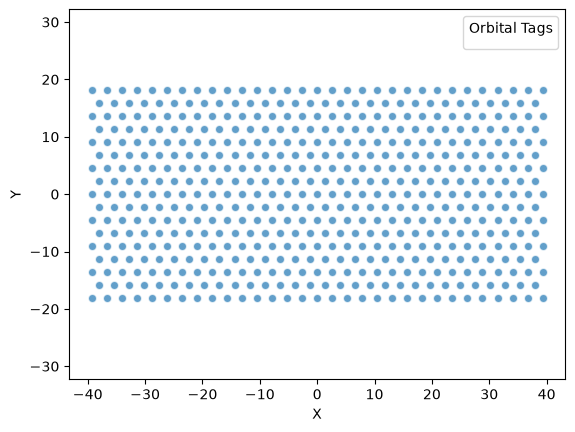

In [5]:
flake = goldene.cut_flake(Rectangle(40, 40))
flake.show_2d(show_index=False)

[-0.22040038 -0.21945842 -0.21888124 -0.21834766 -0.21780135 -0.21575843
 -0.21474203 -0.21433613 -0.21283677 -0.21283563 -0.21226519 -0.20849877
 -0.20817548 -0.20815128 -0.20740515 -0.20666908 -0.20567418 -0.20550082
 -0.20514297 -0.20451643 -0.20291918 -0.20240991 -0.20202795 -0.20200026
 -0.20138458 -0.19780573 -0.19745414 -0.19572999 -0.19385566 -0.19316804
 -0.19304979 -0.19273693 -0.19080817 -0.1907245  -0.19067236 -0.19036599
 -0.19005483 -0.18768732 -0.18707114 -0.18664736]


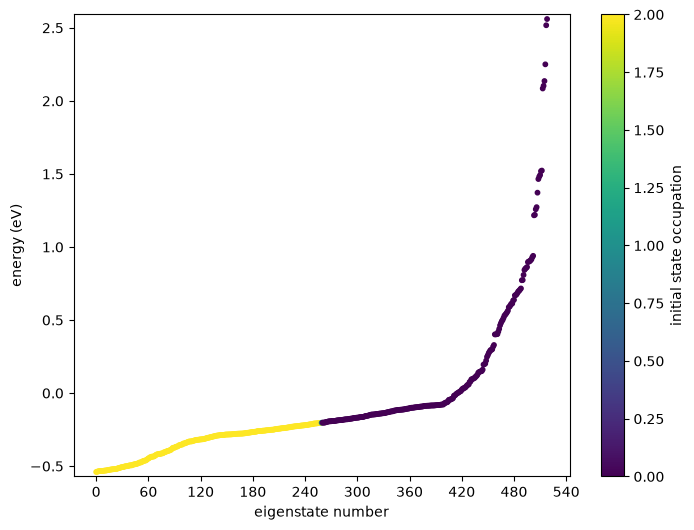

In [6]:
show_energies(flake, figsize=(8,6), circle_scale=10)
print(flake.energies[flake.homo-20 : flake.homo+20])